# Milestone 2, Part 1: Text Encoder and Diffusion Integration

This notebook covers the first Milestone 2 task: **integrate the text encoder with a diffusion model**, and show how text becomes an embedding, the embedding becomes a conditioning signal, and the signal shapes the image.

We use the **pretrained conditional pipeline track**: Stable Diffusion 1.5. We do not call the packaged `StableDiffusionPipeline`. Instead, its parts (CLIP tokenizer, CLIP text encoder, UNet, VAE, noise scheduler) are loaded separately and wired together in `t2i.py`.

| Section | What it shows |
|---|---|
| 2 | Each component loaded separately, with its size and role |
| 3 | One prompt traced from text to token IDs, embeddings, cross-attention, noise prediction and image |
| 4 | Our hand-written denoising loop reproduces the reference `diffusers` pipeline |
| 5 | Ablations proving the conditioning path works: unconditional, shuffled and random embeddings, one-word edits |
| 6 | Cross-attention maps: where each word is read in the image |
| 7 | Saved artifacts |
| 8 | Suggestions for extending this notebook to the remaining Milestone 2 tasks |

Outputs go to `Milestone 2/outputs/`. The notebook needs a CUDA GPU; a Colab T4 is enough.

**TODO (team):** add the measured run time after the first full run.

## 1. Setup

In [ ]:
# Find the repo, move into the notebook folder, and pick a device
import os, sys, subprocess
from pathlib import Path

REPO_URL = "https://github.com/rasmussenj03/IE7615-Group3-Project2.git"
WORK_DIR = "Milestone 2"  # folder holding the notebooks, relative to the repo root
COLAB_USE_DRIVE = True  # False -> clone into /content (outputs are lost when the runtime ends)
COLAB_REPO_DIR = ("/content/drive/MyDrive/IE7615-Group3-Project2" if COLAB_USE_DRIVE
                  else "/content/IE7615-Group3-Project2")

if "google.colab" in sys.modules:
    if COLAB_USE_DRIVE:
        from google.colab import drive
        drive.mount("/content/drive")
    if not Path(COLAB_REPO_DIR, "requirements.txt").is_file():
        from google.colab import userdata
        token = userdata.get("GITHUB_TOKEN")  # Colab secret holding a GitHub access token
        clone = subprocess.run(["git", "clone", "-q", REPO_URL.replace("https://", f"https://{token}@"),
                                COLAB_REPO_DIR], capture_output=True)
        if clone.returncode != 0:
            raise RuntimeError("git clone failed - check the GITHUB_TOKEN secret and repo access")
        subprocess.run(["git", "-C", COLAB_REPO_DIR, "remote", "set-url", "origin", REPO_URL])
    root = Path(COLAB_REPO_DIR)
    # Install the pinned packages (local runs use the .venv instead)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(root / "requirements.txt")],
                   check=True)
else:
    root = Path.cwd()
    while not (root / "requirements.txt").exists() and root != root.parent:
        root = root.parent

PROJECT_ROOT = root
os.chdir(PROJECT_ROOT / WORK_DIR)
sys.path.insert(0, str(Path.cwd()))  # t2i.py and lora.py live next to the notebooks

import torch
if torch.cuda.is_available():
    device = "cuda"
    device_name = "cuda - " + torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = device_name = "mps"
else:
    device = device_name = "cpu"
print("Project root:", PROJECT_ROOT)
print("Working folder:", Path.cwd())
print("PyTorch", torch.__version__, "| device:", device_name)

Mounted at /content/drive
Project root: /content/drive/MyDrive/IE7615-Group3-Project2
Working folder: /content/drive/MyDrive/IE7615-Group3-Project2/Milestone 2
PyTorch 2.8.0+cu128 | device: cuda - Tesla T4


In [ ]:
# Imports
import json
import random
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image

import t2i

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

assert device == "cuda" or os.environ.get("M2_ALLOW_CPU"), \
    "This notebook needs a CUDA GPU (set M2_ALLOW_CPU=1 to try anyway; it will be very slow)"

In [ ]:
# Paths and settings
M1_DIR = Path("..") / "Milestone 1"
BASELINE_DIR = M1_DIR / "Project2_Baseline"
BASELINE_PROMPTS_PATH = BASELINE_DIR / "data" / "baseline_prompts.json"

OUT_DIR = Path("outputs")
LOG_DIR = OUT_DIR / "logs"
FIG_DIR = OUT_DIR / "figures"
for d in (LOG_DIR, FIG_DIR):
    d.mkdir(parents=True, exist_ok=True)

MODEL_ID = t2i.MODEL_ID          # stable-diffusion-v1-5/stable-diffusion-v1-5

with open(BASELINE_PROMPTS_PATH, encoding="utf-8") as f:
    baseline = json.load(f)
prompts = [b["prompt"] for b in baseline]
seeds = [b["generation_seed"] for b in baseline]

env = t2i.environment_info()
t2i.write_json(LOG_DIR / "environment.json", env)
print(json.dumps(env, indent=2))

{
  "python": "3.13.16",
  "platform": "Linux-6.6.159+-x86_64-with-glibc2.39",
  "torch": "2.8.0",
  "diffusers": "0.36.0",
  "transformers": "4.57.6",
  "peft": "0.17.1",
  "accelerate": "1.10.1",
  "safetensors": "0.7.0",
  "gpu": "Tesla T4",
  "gpu_memory_gb": 14.6,
  "cuda": "12.8"
}


## 2. Load the components separately

Instead of one `StableDiffusionPipeline` call, each part is loaded on its own, so the flow between them is explicit in our code:

| Component | Role |
|---|---|
| `CLIPTokenizer` | prompt → 77 token IDs (BPE, padded or truncated) |
| `CLIPTextModel` (ViT-L/14 text tower) | token IDs → per-token embeddings **c** ∈ ℝ^{77×768}, the conditioning signal |
| `UNet2DConditionModel` | predicts the noise ε in a 4×64×64 latent; reads **c** through cross-attention in every transformer block |
| `AutoencoderKL` (VAE) | maps the final latent to a 512×512 RGB image (and images to latents for training) |
| Scheduler config | the training noise schedule (β_t, 1,000 steps), shared by every sampler we try |

In [ ]:
# Load each part and record its size
t0 = time.perf_counter()
c = t2i.load_components(MODEL_ID, device)
load_seconds = time.perf_counter() - t0

arch = t2i.describe_components(c)
arch["load_seconds"] = round(load_seconds, 1)
arch["gpu_memory_after_load_mb"] = t2i.peak_memory_mb(device)
t2i.write_json(LOG_DIR / "architecture.json", arch)

for k, v in arch.items():
    print(f"{k:32s} {v}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

... (3 outputs left out)

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

model_id                         stable-diffusion-v1-5/stable-diffusion-v1-5
device                           cuda
dtype                            torch.float16
tokenizer_max_length             77
text_encoder                     CLIPTextModel
text_encoder_params_M            123.1
text_hidden_size                 768
unet_params_M                    859.5
unet_cross_attention_dim         768
unet_cross_attention_layers      16
vae_params_M                     83.7
vae_scaling_factor               0.18215
latent_shape                     [4, 64, 64]
image_size                       [512, 512]
train_noise_schedule             {'num_train_timesteps': 1000, 'beta_schedule': 'scaled_linear', 'beta_start': 0.00085, 'beta_end': 0.012, 'prediction_type': None}
load_seconds                     57.7
gpu_memory_after_load_mb         2056.6


In [ ]:
# Every cross-attention layer: where the text embeddings enter the UNet
xattn = t2i.cross_attention_layers(c.unet)
by_stage = {}
for layer in xattn:
    key = (layer["stage"], layer["query_dim"])
    by_stage[key] = by_stage.get(key, 0) + 1

ctx = f"{c.tokenizer.model_max_length}x{c.text_encoder.config.hidden_size}"
print(f"{len(xattn)} cross-attention layers; every one takes the {ctx} text context as keys and values")
print(f"{'UNet stage':12s} {'query dim':>10s} {'heads':>6s} {'layers':>7s}")
for (stage, qdim), n in by_stage.items():
    heads = next(l["heads"] for l in xattn if l["stage"] == stage and l["query_dim"] == qdim)
    print(f"{stage:12s} {qdim:10d} {heads:6d} {n:7d}")

16 cross-attention layers; every one takes the 77x768 text context as keys and values
UNet stage    query dim  heads  layers
down_blocks         320      8       2
down_blocks         640      8       2
down_blocks        1280      8       2
up_blocks          1280      8       3
up_blocks           640      8       3
up_blocks           320      8       3
mid_block          1280      8       1


## 3. Trace one prompt from text to image

Forward hooks record the tensor shape at each hand-off, so the reviewer can follow the text → embedding → conditioning → image flow with real numbers.

In [ ]:
# Tokenize: prompt -> 77 token IDs
prompt, seed = prompts[0], seeds[0]
ids = t2i.tokenize(c, [prompt]).input_ids
n_tokens = len(c.tokenizer(prompt).input_ids)
print("Prompt:", prompt)
print("Token IDs shape:", tuple(ids.shape), f"| {n_tokens} real tokens incl. start/end, rest is padding")
print("Tokens:", c.tokenizer.convert_ids_to_tokens(ids[0][:n_tokens]))

report = t2i.token_report(c, prompts)
print(f"\nBaseline prompts: longest {max(r['tokens'] for r in report)} tokens, "
      f"{sum(r['truncated'] for r in report)} truncated at {c.tokenizer.model_max_length}")

Prompt: there is a large book shelf in this living room
Token IDs shape: (1, 77) | 12 real tokens incl. start/end, rest is padding
Tokens: ['<|startoftext|>', 'there</w>', 'is</w>', 'a</w>', 'large</w>', 'book</w>', 'shelf</w>', 'in</w>', 'this</w>', 'living</w>', 'room</w>', '<|endoftext|>']

Baseline prompts: longest 19 tokens, 0 truncated at 77


In [ ]:
# Encode: token IDs -> per-token embeddings (the conditioning signal)
cond = t2i.encode_prompt(c, [prompt])
uncond = t2i.encode_prompt(c, [""])
print("Text embeddings c:", tuple(cond.shape), cond.dtype)
print(f"mean {cond.float().mean():.3f} | std {cond.float().std():.3f}")
# The unconditional embedding of "" is not zero: CFG contrasts c against this learned 'no text' context
diff = (cond - uncond).float().norm(dim=-1)[0]
print("Per-token distance between prompt and empty-prompt embeddings (first 12 positions):")
print(np.round(diff[:12].cpu().numpy(), 1))

Text embeddings c: (1, 77, 768) torch.float16
mean -0.111 | std 1.025
Per-token distance between prompt and empty-prompt embeddings (first 12 positions):
[ 0.  35.7 35.8 37.1 39.3 38.5 38.8 38.4 37.4 38.3 38.8 35.3]


In [ ]:
# One UNet call with hooks: noisy latent + timestep + text context -> predicted noise
trace = []
def hook(label):
    def fn(module, inputs, output):
        trace.append((label, tuple(inputs[0].shape), tuple(output.shape)))
    return fn

first = c.unet.get_submodule(xattn[0]["name"])
handles = [
    c.unet.conv_in.register_forward_hook(hook("unet.conv_in            (noisy latent in)")),
    first.to_q.register_forward_hook(hook(f"{xattn[0]['name']}.to_q (image features -> queries)")),
    first.to_k.register_forward_hook(hook(f"{xattn[0]['name']}.to_k (text embeddings -> keys)")),
    first.to_v.register_forward_hook(hook(f"{xattn[0]['name']}.to_v (text embeddings -> values)")),
    c.unet.conv_out.register_forward_hook(hook("unet.conv_out           (predicted noise out)")),
]
with torch.no_grad():
    z_T, _ = t2i.initial_latents(c, [seed], 512, 512)
    context = torch.cat([uncond, cond])          # batch of 2: unconditional + conditional branch
    eps = c.unet(torch.cat([z_T] * 2), 999, encoder_hidden_states=context).sample
for h in handles:
    h.remove()

print("Initial noise z_T:", tuple(z_T.shape))
print("Context [uncond; cond]:", tuple(context.shape))
for label, i, o in trace:
    print(f"{label:62s} in {str(i):22s} out {o}")
eps_u, eps_c = eps.chunk(2)
print("eps_uncond, eps_cond:", tuple(eps_u.shape), "| guidance direction RMS:",
      f"{(eps_c - eps_u).float().pow(2).mean().sqrt():.4f}")

Initial noise z_T: (1, 4, 64, 64)
Context [uncond; cond]: (2, 77, 768)
unet.conv_in            (noisy latent in)                      in (2, 4, 64, 64)         out (2, 320, 64, 64)
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_q (image features -> queries) in (2, 4096, 320)         out (2, 4096, 320)
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_k (text embeddings -> keys) in (2, 77, 768)           out (2, 77, 320)
down_blocks.0.attentions.0.transformer_blocks.0.attn2.to_v (text embeddings -> values) in (2, 77, 768)           out (2, 77, 320)
unet.conv_out           (predicted noise out)                  in (2, 320, 64, 64)       out (2, 4, 64, 64)
eps_uncond, eps_cond: (1, 4, 64, 64) | guidance direction RMS: 0.0059


Settings: {'sampler': 'ddim', 'scheduler_class': 'DDIMScheduler', 'num_inference_steps': 50, 'guidance_scale': 7.5, 'height': 512, 'width': 512, 'negative_prompt': '', 'eta': 0.0, 'scheduler_overrides': {}, 'unet_passes_per_step': 2}
Timings: {'encode_s': 0.019, 'denoise_s': 6.564, 'decode_s': 0.3, 'total_s': 6.883, 'per_image_s': 6.883, 'batch_size': 1} | peak GPU memory (MB): 2676.0


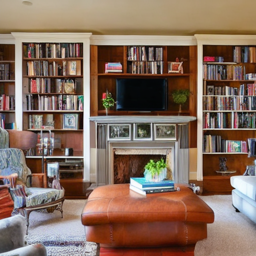

In [ ]:
# Full generation for the same prompt and seed with our loop
res = t2i.generate(c, [prompt], [seed], sampler="ddim", num_inference_steps=50, guidance_scale=7.5)
print("Settings:", res.settings)
print("Timings:", res.timings, "| peak GPU memory (MB):", res.peak_memory_mb)
res.images[0].resize((256, 256))

## 4. Our loop reproduces the reference pipeline

`t2i.generate` re-implements what `StableDiffusionPipeline.__call__` does (encode, seeded noise, guided denoising, decode). Running both on the same components, prompts, seeds and DDIM scheduler should give the same images, up to fp16 rounding. This confirms the hand-wired integration is correct before we start changing parts of it.

max |diff| =   0/255 | PSNR =    inf dB | there is a large book shelf in this living room
max |diff| =   0/255 | PSNR =    inf dB | A man riding on the back of a brown horse through a lush green field.
max |diff| =   0/255 | PSNR =    inf dB | A hot dog with sour kraut on a plate.


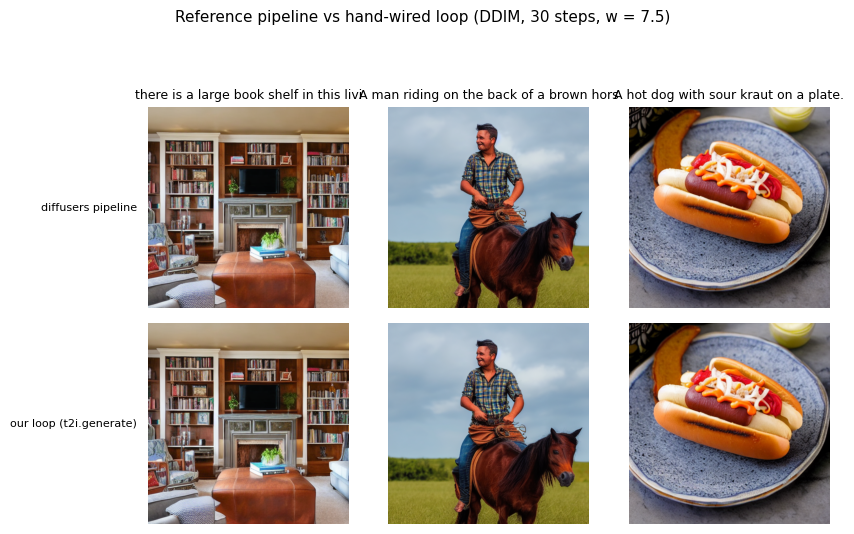

In [ ]:
# Same components, same seeds: diffusers pipeline vs our loop
from diffusers import StableDiffusionPipeline

ref_pipe = StableDiffusionPipeline(
    vae=c.vae, text_encoder=c.text_encoder, tokenizer=c.tokenizer, unet=c.unet,
    scheduler=t2i.make_scheduler("ddim", c.scheduler_config),
    safety_checker=None, feature_extractor=None, requires_safety_checker=False,
)
ref_pipe.set_progress_bar_config(disable=True)

check_prompts, check_seeds = prompts[:3], seeds[:3]
gens = [torch.Generator("cpu").manual_seed(s) for s in check_seeds]
ref_images = ref_pipe(check_prompts, num_inference_steps=30, guidance_scale=7.5, generator=gens).images
our_images = t2i.generate(c, check_prompts, check_seeds, "ddim", 30, 7.5).images

equivalence = []
for p, a, b in zip(check_prompts, ref_images, our_images):
    max_diff = int(np.abs(np.asarray(a, dtype=int) - np.asarray(b, dtype=int)).max())
    equivalence.append({"prompt": p, "max_abs_pixel_diff": max_diff, "psnr_db": t2i.psnr(a, b)})
    print(f"max |diff| = {max_diff:3d}/255 | PSNR = {t2i.psnr(a, b):6.1f} dB | {p}")
t2i.write_json(LOG_DIR / "equivalence_check.json", equivalence)

fig = t2i.labeled_grid([ref_images, our_images], ["diffusers pipeline", "our loop (t2i.generate)"],
                       [p[:40] for p in check_prompts], title="Reference pipeline vs hand-wired loop (DDIM, 30 steps, w = 7.5)")
fig.savefig(FIG_DIR / "01_equivalence_check.png", dpi=120, bbox_inches="tight")
plt.show()
del ref_pipe

## 5. Is the conditioning path doing the work?

A diffusion model can produce plausible images with no text at all, so plausible images alone do not prove the text is used. We hold the seed fixed and change only the conditioning:

| Condition | Context passed to the UNet | Guidance |
|---|---|---|
| **text + CFG** | CLIP(prompt) | w = 7.5 |
| **text, no CFG** | CLIP(prompt) | w = 1 (conditional branch only) |
| **unconditional** | CLIP("") | w = 1 |
| **shuffled text** | CLIP(a *different* baseline prompt) | w = 7.5 |
| **random context** | Gaussian noise with the embeddings' mean and std | w = 7.5 |

Each image is scored with **CLIP ViT-B/32**, the Milestone 1 model, which is a different network from the ViT-L/14 text encoder that conditions Stable Diffusion. *CLIP score* is 100 × cosine(image, intended prompt). *Top-1* is the share of images whose intended prompt is the closest of all 20 baseline prompts (chance = 5%). For the shuffled condition we also score against the prompt whose embedding was actually used.

In [ ]:
# Generate every condition for 8 prompts x 2 seeds
ABL_IDX = list(range(8))
ABL_SEEDS = [0, 1]                       # offsets added to each prompt's generation seed
abl_prompts = [prompts[i] for i in ABL_IDX]
shift = {i: ABL_IDX[(k + 3) % len(ABL_IDX)] for k, i in enumerate(ABL_IDX)}   # derangement for "shuffled"

with torch.no_grad():
    text_emb = t2i.encode_prompt(c, abl_prompts)
    g = torch.Generator("cpu").manual_seed(SEED)
    rand_emb = (torch.randn(text_emb.shape, generator=g) * text_emb.float().std().item()
                + text_emb.float().mean().item()).to(device, c.dtype)
shuffled_emb = torch.stack([text_emb[ABL_IDX.index(shift[i])] for i in ABL_IDX])

conditions = {
    "text + CFG": dict(prompts=abl_prompts, guidance_scale=7.5),
    "text, no CFG": dict(prompts=abl_prompts, guidance_scale=1.0),
    "unconditional": dict(prompts=[""] * len(abl_prompts), guidance_scale=1.0),
    "shuffled text": dict(prompts=abl_prompts, guidance_scale=7.5, prompt_embeds=shuffled_emb),
    "random context": dict(prompts=abl_prompts, guidance_scale=7.5, prompt_embeds=rand_emb),
}
abl_images = {}
for name, kw in conditions.items():
    abl_images[name] = []
    for off in ABL_SEEDS:
        run_seeds = [seeds[i] + off for i in ABL_IDX]
        out = t2i.generate(c, kw["prompts"], run_seeds, "ddim", 30, kw["guidance_scale"],
                           prompt_embeds=kw.get("prompt_embeds"))
        abl_images[name] += out.images        # ordered [seed0 x 8 prompts, seed1 x 8 prompts]
    print(f"{name:15s} done")

text + CFG      done
text, no CFG    done
unconditional   done
shuffled text   done
random context  done


In [ ]:
# Score with the Milestone 1 CLIP model
scorer = t2i.ClipScorer(device=device)
all_text = scorer.text_embeds(prompts)                      # 20 candidate prompts
targets = [i for _ in ABL_SEEDS for i in ABL_IDX]           # intended prompt index for each image
shifted = [shift[i] for _ in ABL_SEEDS for i in ABL_IDX]    # prompt actually encoded in "shuffled"

ablation = []
for name, imgs in abl_images.items():
    emb = scorer.image_embeds(imgs)
    row = {"condition": name,
           "clip_score": float((100 * (emb * all_text[targets]).sum(-1)).mean()),
           "top1_intended": t2i.retrieval_top1(emb, all_text, targets)}
    if name == "shuffled text":
        row["clip_score_vs_used_prompt"] = float((100 * (emb * all_text[shifted]).sum(-1)).mean())
        row["top1_used_prompt"] = t2i.retrieval_top1(emb, all_text, shifted)
    ablation.append(row)

# Ceiling: the real COCO photos against their own captions
ref_imgs = [Image.open(BASELINE_DIR / baseline[i]["local_reference_image"]).convert("RGB") for i in ABL_IDX]
ref_emb = scorer.image_embeds(ref_imgs)
ablation.append({"condition": "real COCO photo (ceiling)",
                 "clip_score": float((100 * (ref_emb * all_text[ABL_IDX]).sum(-1)).mean()),
                 "top1_intended": t2i.retrieval_top1(ref_emb, all_text, ABL_IDX)})
t2i.write_json(LOG_DIR / "conditioning_ablation.json", ablation)

print(f"{'condition':28s} {'CLIP score':>10s} {'top-1':>6s}")
for r in ablation:
    extra = (f"   (vs prompt actually used: {r['clip_score_vs_used_prompt']:.1f}, top-1 {r['top1_used_prompt']:.0%})"
             if "clip_score_vs_used_prompt" in r else "")
    print(f"{r['condition']:28s} {r['clip_score']:10.1f} {r['top1_intended']:6.0%}{extra}")

config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/605M [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


model.safetensors:   0%|          | 0.00/605M [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/592 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

condition                    CLIP score  top-1
text + CFG                         31.1   100%
text, no CFG                       26.2    75%
unconditional                      14.3     6%
shuffled text                      16.4     0%   (vs prompt actually used: 31.9, top-1 100%)
random context                     17.9     0%
real COCO photo (ceiling)          29.8    88%


In [ ]:
# Grid: rows = prompts (first seed), columns = conditions
n = len(ABL_IDX)
rows = [[abl_images[name][k] for name in conditions] for k in range(n)]
fig = t2i.labeled_grid(rows, abl_prompts, list(conditions), cell=2.0,
                       title="Same seed, different conditioning (DDIM 30 steps)")
fig.savefig(FIG_DIR / "02_conditioning_ablation.png", dpi=110, bbox_inches="tight")
plt.show()

Output hidden; open in https://colab.research.google.com to view.

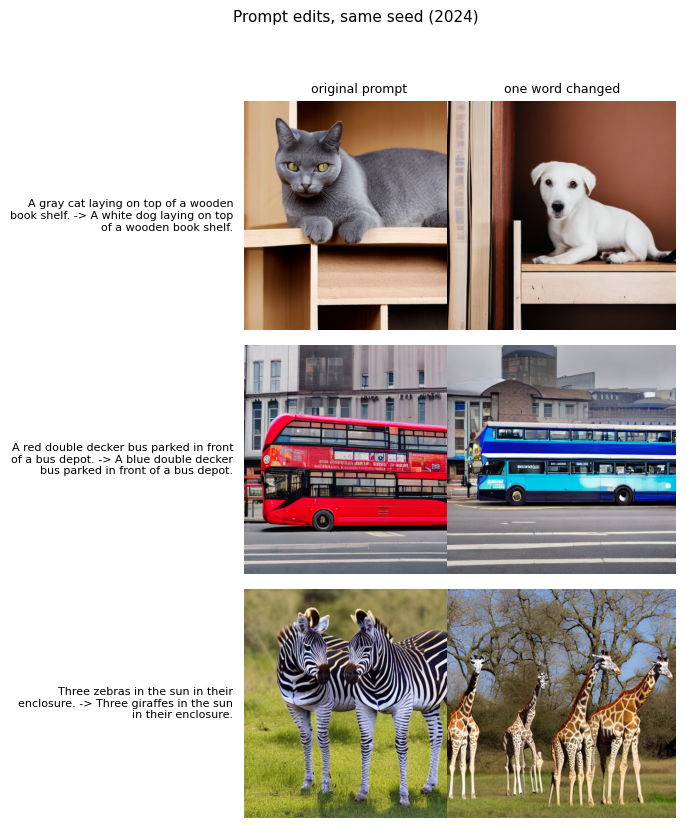

In [ ]:
# One-word edits with the seed held fixed: the change should follow the edited word
edits = [
    ("A gray cat laying on top of a wooden book shelf.", "A white dog laying on top of a wooden book shelf."),
    ("A red double decker bus parked in front of a bus depot.", "A blue double decker bus parked in front of a bus depot."),
    ("Three zebras in the sun in their enclosure.", "Three giraffes in the sun in their enclosure."),
]
edit_rows, edit_labels = [], []
for a, b in edits:
    out = t2i.generate(c, [a, b], [2024, 2024], "ddim", 30, 7.5)
    edit_rows.append(out.images)
    edit_labels.append(f"{a}\n-> {b}")
fig = t2i.labeled_grid(edit_rows, edit_labels, ["original prompt", "one word changed"], cell=2.6,
                       row_label_width=40, title="Prompt edits, same seed (2024)")
fig.savefig(FIG_DIR / "03_prompt_edits.png", dpi=110, bbox_inches="tight")
plt.show()

**Observations (TODO after the run):**


## 6. Cross-attention maps

A custom attention processor records the cross-attention probabilities at the 16×16 UNet resolution (averaged over heads, layers and steps) for the conditional branch. Each map shows which image regions read a given prompt token. Content words should light up on the matching objects.

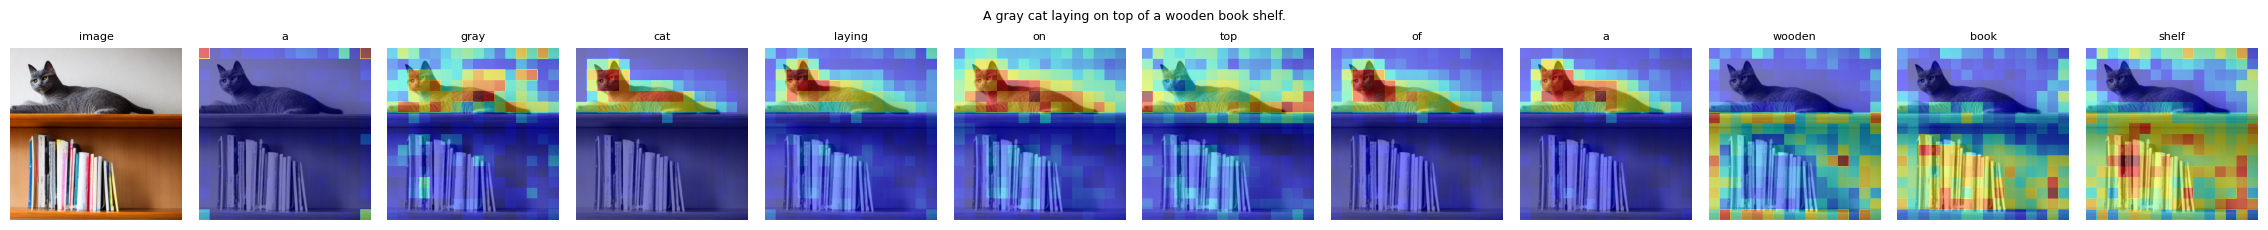

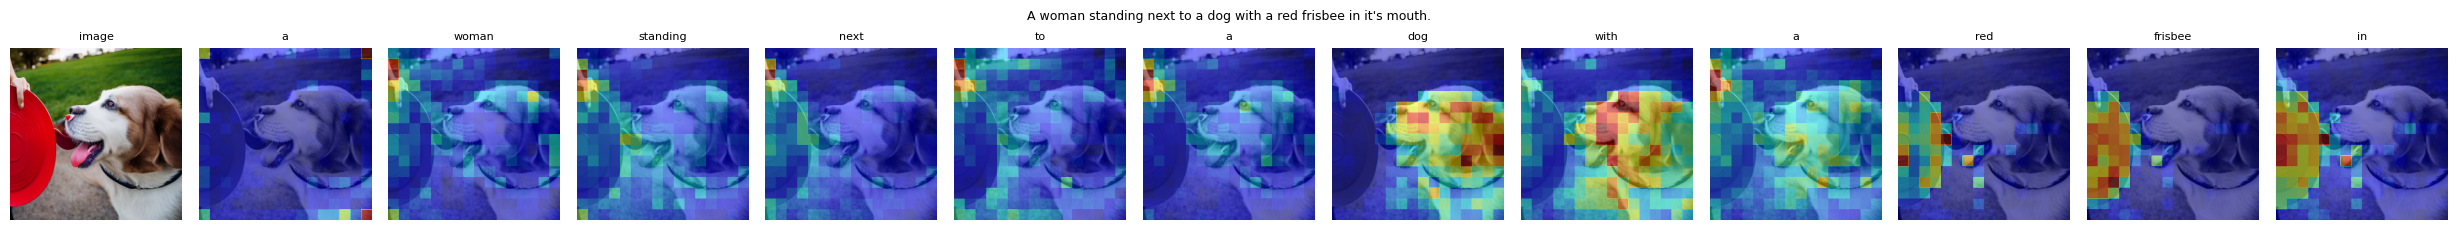

In [ ]:
# Attention maps for two prompts
for k, idx in enumerate([5, 13]):                   # cat on shelf, woman with dog and frisbee
    img, tokens, maps = t2i.cross_attention_maps(c, prompts[idx], seeds[idx])
    keep = [k for k, tok in enumerate(tokens) if any(ch.isalnum() for ch in tok)][:12]   # words only
    fig, axes = plt.subplots(1, len(keep) + 1, figsize=(1.9 * (len(keep) + 1), 2.3))
    axes[0].imshow(img); axes[0].set_title("image", fontsize=8)
    for ax, tok, m in zip(axes[1:], [tokens[k] for k in keep], maps[keep]):
        ax.imshow(img.resize((256, 256)).convert("L"), cmap="gray")
        ax.imshow(np.kron(m / m.max(), np.ones((16, 16))), cmap="jet", alpha=0.5)
        ax.set_title(tok, fontsize=8)
    for ax in axes:
        ax.axis("off")
    fig.suptitle(prompts[idx], fontsize=9)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"04_cross_attention_{k + 1}.png", dpi=110, bbox_inches="tight")
    plt.show()

## 7. Saved artifacts

In [ ]:
# Everything this notebook wrote
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"{p.stat().st_size / 1024:8.1f} KB  {p}")

   686.7 KB  outputs/figures/01_equivalence_check.png
  3442.6 KB  outputs/figures/02_conditioning_ablation.png
   724.7 KB  outputs/figures/03_prompt_edits.png
   338.5 KB  outputs/figures/04_cross_attention_1.png
   375.1 KB  outputs/figures/04_cross_attention_2.png
     0.7 KB  outputs/logs/architecture.json
     0.7 KB  outputs/logs/conditioning_ablation.json
     0.3 KB  outputs/logs/environment.json
     0.4 KB  outputs/logs/equivalence_check.json


## 8. Next steps: extending this notebook

This notebook delivers the integration itself. The rest of Milestone 2 can build on it as follows.

### 8.1 Modify the conditioning path (strengthens Task 1, "Model Integration", 35 pts)
The Milestone spec asks pretrained-track teams to "fine-tune or modify its conditioning path". The pipeline above uses the pretrained weights unchanged. `lora.py` adds rank-8 LoRA adapters to the 16 cross-attention blocks (the only place text enters the UNet) and trains them on the Milestone 1 COCO subset.
- Hold out the 20 baseline images: `lora.split_records(records, {b["coco_image_id"] for b in baseline}, n_train)`.
- Make sure the images exist: `lora.ensure_images(...)` downloads any missing ones from cocodataset.org.
- Train: `lora.train_lora(c, train_records, val_records, COCO_DIR, lora.TrainConfig(max_steps=1500), OUT_DIR / "lora_run", sample_prompts, sample_seeds)`. This takes about 35 to 45 minutes on a T4 and writes `train_log.csv`, `val_log.csv`, `summary.json`, sample sheets and the adapter weights.
- Compare base and fine-tuned models on the held-out prompts by calling `c.unet.disable_adapters()` / `c.unet.enable_adapters()` around `t2i.generate`, and score both with the Section 5 CLIP scorer.
- Add the fine-tune to the write-up's "Modifications" section and to the diagram (the dashed branch in `docs/architecture.svg` already shows it).

### 8.2 Training logs and sampler diagnostics (Task 5, "Training Logs & Summary", 15 pts)
- **Loss curves:** plot `train_log.csv` (raw plus EMA) and `val_log.csv`. The validation loss uses fixed timesteps and noise, so it is much smoother; also plot it per timestep to see where the fine-tune helps.
- **Sampler diagnostics** (the spec's alternative to loss curves for inference-only runs): `t2i.generate(..., track=True, x0_preview_steps=[0, 10, 20, 30, 49])` records latent std, guided ε RMS and ‖ε_cond − ε_uncond‖ per step, plus decoded x̂₀ previews. Plot them for DDIM, DDPM and DPM-Solver++ on the same seed.
- **Runtime and memory:** every `GenerationResult` already carries `timings` and `peak_memory_mb`, and `summary.json` records training minutes, s/step, peak memory and any fp16 overflow events. Collect them into the table in `docs/training_logs_summary.md`.

### 8.3 Noise-schedule background (supports Task 4)
`t2i.schedule_curves(c.scheduler_config)` returns ᾱ_t and log-SNR for the SD 1.5 training schedule (`scaled_linear`), the DDPM linear schedule and the cosine schedule. A two-panel plot of these explains why a pretrained model's schedule is fixed, and why our schedule experiments vary the *sampler side* (Part 2, Section 3).

### 8.4 Before submission
- Replace every **TODO** observation in Section 5 with what the run showed. The shuffled-text result (does the image follow the embedding that was actually used?) is the key evidence that the conditioning pathway works.
- Copy the equivalence and ablation numbers from `outputs/logs/` into `docs/integration_writeup.md`, Section 4.